# 01 Dome Reflections and Focusing

**Series:** Physics of the Integratron (Landers, California)
**Topic T1:** why a curved dome sends sound back to a single spot, and why the sound there is so loud.

The Integratron is a wooden dome 55 ft (16.8 m) across and 38 ft (11.6 m) tall. Its upper room is known for strong acoustics. A whisper on one side is clearly heard at a matching spot on the other side, and a voice at the centre comes straight back to the speaker. This notebook explains both effects with pictures.

1. **The shape.** A dome over a flat floor behaves like a complete sphere.
2. **Rays.** A concave wall sends sound from a point near the centre to a mirror point on the other side.
3. **Constructive interference.** At the mirror point, sound from every part of the wall arrives in step, so the waves add.
4. **The interference pattern.** A map of loud and quiet spots across the room, and how sharp the hot spot is.
5. **A pulse in the dome.** A simulated clap travels out, reflects, and refocuses.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from ipywidgets import interact, FloatSlider, IntSlider

SPEED_OF_SOUND = 343.0                   # m/s, air at 20 °C
DOME_RADIUS = 55 * 0.3048 / 2            # 55 ft diameter -> 8.38 m
DOME_HEIGHT = 38 * 0.3048                # 38 ft to the top -> 11.58 m
DRUM_HEIGHT = DOME_HEIGHT - DOME_RADIUS  # wall under the dome -> 3.2 m

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
SLIDER_STYLE = {"handle_color": BLUE}  # visible knob on white backgrounds
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "lines.linewidth": 2,
})

R = DOME_RADIUS
print(f"Dome radius {R:.2f} m, drum height {DRUM_HEIGHT:.2f} m")
print(f"Time for sound to cross the dome and back, 2R/c = {2 * R / SPEED_OF_SOUND * 1000:.1f} ms")

Dome radius 8.38 m, drum height 3.20 m
Time for sound to cross the dome and back, 2R/c = 48.9 ms


## 1. The shape: a dome over a floor is a sphere

The model in this notebook:

- The dome is a hemisphere of radius $R = 8.4$ m sitting on a 3.2 m cylindrical wall. These two numbers reproduce the published 55 ft width and 38 ft height.
- The upper floor is at the base of the hemisphere, so the floor passes through the sphere's centre.
- The walls are hard and reflect all the sound. The real room has windows, wooden ribs and people, which the model ignores.

The floor is flat and hard, so it acts as a mirror. Sound that bounces off the floor behaves as if it came from a **mirror-image dome** below the floor. The real dome plus its image is a **complete sphere**. That means everything below can be worked out for a full sphere, or for a full circle in a vertical slice through the centre, and the half above the floor is the real room.

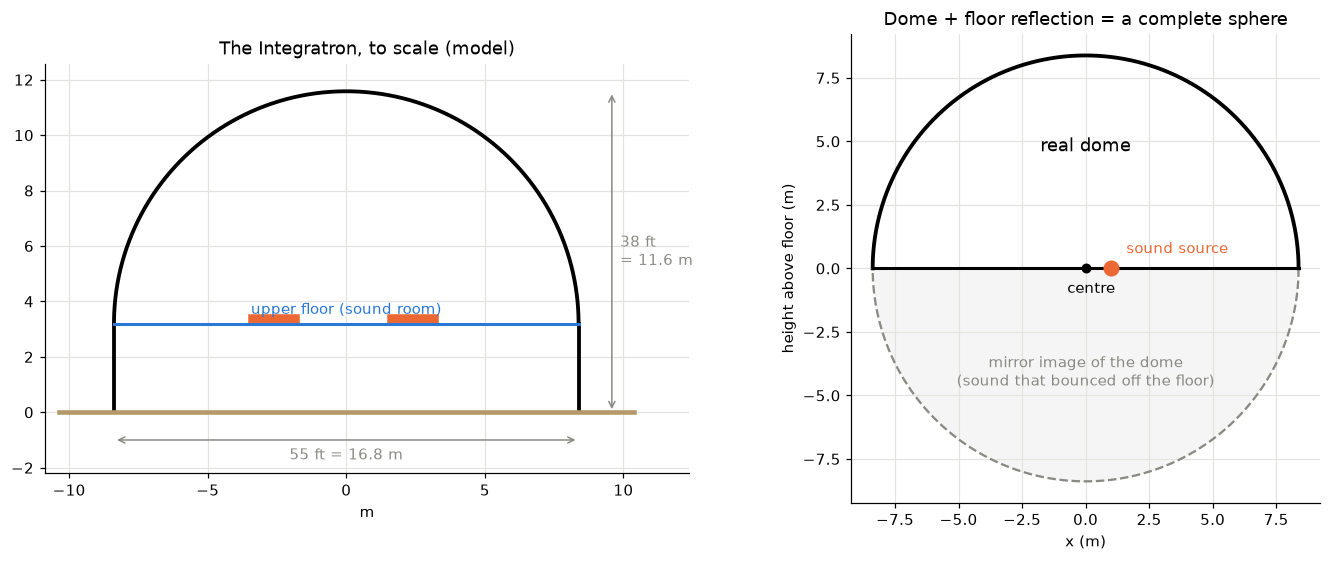

In [2]:
def draw_circle(ax, radius=R, **style):
    phi = np.linspace(0, 2 * np.pi, 400)
    ax.plot(radius * np.cos(phi), radius * np.sin(phi), **style)


def draw_room(ax, show_image=True):
    # Real dome above the floor, its floor-mirror image below
    phi = np.linspace(0, np.pi, 200)
    ax.plot(R * np.cos(phi), R * np.sin(phi), color="k", linewidth=2.5)
    if show_image:
        ax.plot(R * np.cos(phi), -R * np.sin(phi), color=GREY, linewidth=1.5,
                linestyle="--")
        ax.fill_between(R * np.cos(phi), -R * np.sin(phi), 0, color=GREY,
                        alpha=0.08, linewidth=0)
    ax.plot([-R, R], [0, 0], color="k", linewidth=2)
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("height above floor (m)")


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2))

# Left: the building to scale
phi = np.linspace(0, np.pi, 200)
ax1.plot(R * np.cos(phi), DRUM_HEIGHT + R * np.sin(phi), color="k", linewidth=2.5)
for side in (-R, R):
    ax1.plot([side, side], [0, DRUM_HEIGHT], color="k", linewidth=2.5)
ax1.plot([-R - 2, R + 2], [0, 0], color="#b49a6a", linewidth=3)
ax1.plot([-R, R], [DRUM_HEIGHT, DRUM_HEIGHT], color=BLUE, linewidth=2)
ax1.text(0, DRUM_HEIGHT + 0.35, "upper floor (sound room)", ha="center", color=BLUE)
ax1.annotate("", xy=(-R, -1.0), xytext=(R, -1.0),
             arrowprops=dict(arrowstyle="<->", color=GREY))
ax1.text(0, -1.7, f"55 ft = {2 * R:.1f} m", ha="center", color=GREY)
ax1.annotate("", xy=(R + 1.2, 0), xytext=(R + 1.2, DOME_HEIGHT),
             arrowprops=dict(arrowstyle="<->", color=GREY))
ax1.text(R + 1.5, DOME_HEIGHT / 2, f"38 ft\n= {DOME_HEIGHT:.1f} m", va="center",
         color=GREY)
for x0 in (-3.5, 1.5):  # two people lying on the floor, for scale
    ax1.add_patch(plt.Rectangle((x0, DRUM_HEIGHT), 1.8, 0.3, color=ORANGE))
ax1.set_aspect("equal")
ax1.set_xlim(-R - 2.5, R + 4)
ax1.set_ylim(-2.2, DOME_HEIGHT + 1)
ax1.set_title("The Integratron, to scale (model)")
ax1.set_xlabel("m")

# Right: the floor acts as a mirror, so the room behaves like a full sphere
draw_room(ax2)
source = np.array([1.0, 0.0])
ax2.scatter(*source, s=90, color=ORANGE, zorder=4)
ax2.annotate("sound source", source, xytext=(10, 10), textcoords="offset points",
             color=ORANGE)
ax2.text(0, R * 0.55, "real dome", ha="center", fontsize=12)
ax2.text(0, -R * 0.55, "mirror image of the dome\n(sound that bounced off the floor)",
         ha="center", color=GREY)
ax2.scatter([0], [0], s=30, color="k", zorder=4)
ax2.annotate("centre", (0, 0), xytext=(-12, -16), textcoords="offset points")
ax2.set_title("Dome + floor reflection = a complete sphere")
plt.tight_layout()
plt.show()

**What the figure shows**

- **Left:** the building drawn to scale. The black outline is the hemisphere sitting on its 3.2 m wall. The blue line is the upper floor, where the sound room is. The two orange bars are people lying on that floor, 1.8 m long. The room is about nine body lengths across.
- **Right:** the sound room on its own. The horizontal line is the floor, and the black dot is the centre of the sphere, which sits on the floor. The orange dot is a sound source on the floor 1 m from the centre. The dashed grey half circle is the floor's mirror image of the dome. Sound that bounces off the floor travels as if it came from that image.

Every later plot uses the right-hand view: x runs across the room, height above the floor runs up, and the floor is at height 0.

## 2. Rays: the wall sends sound to a mirror point

Treat sound as rays leaving the source in every direction. Each ray hits the wall and reflects with equal angles to the wall's normal. The normal of a sphere always points at the centre.

- A source **at the centre** sends every ray straight out along a normal. Every ray comes straight back to the centre, all at the same moment.
- A source **near the centre** at distance $d$ sends rays that cross again in a small knot around the **mirror point** at $-d$, on the other side of the centre.
- A source **far from the centre** gives no single crossing point. The reflected rays form a curved bright envelope called a **caustic**, and the sound is spread along it.

The left plot shows the rays in a vertical slice through the centre. Rays in the shaded lower half are the ones that bounced off the floor. The right plot shows where reflected rays come down onto the floor, using only rays that start upward into the real dome.

In [3]:
def trace_rays(source, angles, n_bounces):
    # Follow rays inside a circle of radius R. Returns (n_rays, n_bounces + 2, 2):
    # the source, each wall hit, and the next wall point after the last bounce.
    pos = np.tile(np.asarray(source, float), (len(angles), 1))
    direction = np.column_stack([np.cos(angles), np.sin(angles)])
    points = [pos]
    for bounce in range(n_bounces + 1):
        # Distance along the ray to the wall: solve |pos + t*direction| = R
        b = np.sum(pos * direction, axis=1)
        c = np.sum(pos ** 2, axis=1) - R ** 2
        t = -b + np.sqrt(b ** 2 - c)
        pos = pos + t[:, None] * direction
        points.append(pos)
        normal = pos / R
        direction = direction - 2 * np.sum(direction * normal, axis=1)[:, None] * normal
    return np.stack(points, axis=1)


def floor_landings(paths):
    # x where the first reflected leg (wall hit -> next wall) crosses the floor
    start, end = paths[:, 1], paths[:, 2]
    crosses = start[:, 1] * end[:, 1] < 0
    frac = -start[crosses, 1] / (end[crosses, 1] - start[crosses, 1])
    return start[crosses, 0] + frac * (end[crosses, 0] - start[crosses, 0])


LEG_COLOURS = [ORANGE, BLUE, AQUA, GREY]


@interact(
    offset_m=FloatSlider(value=1.0, min=0.0, max=6.0, step=0.25,
                         description="source d (m)", continuous_update=False,
                         style=SLIDER_STYLE),
    n_rays=IntSlider(value=120, min=20, max=400, step=20, description="rays",
                     continuous_update=False, style=SLIDER_STYLE),
    n_bounces=IntSlider(value=1, min=1, max=3, description="bounces",
                        continuous_update=False, style=SLIDER_STYLE),
)
def show_rays(offset_m, n_rays, n_bounces):
    source = np.array([offset_m, 0.0])
    angles = np.linspace(0, 2 * np.pi, n_rays, endpoint=False) + np.pi / n_rays
    paths = trace_rays(source, angles, n_bounces)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.4),
                                   gridspec_kw={"width_ratios": [1.25, 1]})
    draw_room(ax1)
    for leg in range(n_bounces + 1):
        segments = paths[:, leg:leg + 2]
        ax1.add_collection(LineCollection(segments, colors=LEG_COLOURS[leg],
                                          linewidths=0.7, alpha=0.45))
    ax1.scatter(*source, s=90, color=ORANGE, zorder=4, label="source")
    ax1.scatter(-offset_m, 0, s=160, marker="*", color=BLUE, zorder=4,
                label="mirror point")
    ax1.set_xlim(-R * 1.05, R * 1.05)
    ax1.set_ylim(-R * 1.05, R * 1.05)
    ax1.grid(False)
    ax1.legend(loc="upper right", fontsize=8)
    legs = ", ".join(["orange: out", "blue: 1st reflection", "green: 2nd",
                      "grey: 3rd"][:n_bounces + 1])
    ax1.set_title(f"Ray paths ({legs})", fontsize=10)

    upward = (angles > 0) & (angles < np.pi)
    landings = floor_landings(trace_rays(source, angles[upward], 1))
    ax2.hist(landings, bins=np.linspace(-R, R, 85), color=BLUE)
    ax2.axvline(-offset_m, color=BLUE, linestyle="--", linewidth=1)
    ax2.axvline(offset_m, color=ORANGE, linestyle="--", linewidth=1)
    ax2.text(-offset_m, ax2.get_ylim()[1] * 0.95, " mirror point", color=BLUE,
             va="top")
    ax2.text(offset_m, ax2.get_ylim()[1] * 0.85, " source", color=ORANGE, va="top")
    ax2.set_xlabel("x on the floor (m)")
    ax2.set_ylabel("number of reflected rays landing")
    ax2.set_title("Where the first reflection lands on the floor")
    plt.tight_layout()
    plt.show()

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='source d (m)', max=6.0, ste…

**What the plots show** (defaults: source 1 m right of centre, 120 rays, one bounce)

- **Left:** orange lines run from the source out to the wall. Blue lines are the same rays after one reflection. The blue lines pinch into a tight knot around the blue star at x = −1 m. That knot is the focus. Everywhere else the rays are spread evenly, so no other spot gets extra sound.
- **Right:** a histogram of where the reflected rays hit the floor. Each bar counts the rays landing in a 0.2 m strip. All 60 upward rays land between −1.5 m and −0.9 m, around the mirror point. None land anywhere else on the floor.

**Try this:**

- Set $d = 0$. Every ray returns to the centre and the histogram is a single bar at 0.
- Set $d = 2$ m. The knot opens into a pointed curve: the caustic. Landings spread from −4 m to −1.3 m, and the tallest bar is near −1.5 m, inside the mirror point. Rays from the far wall focus closer to the centre than rays from the near wall, so there is no single focus. This is **spherical aberration**.
- Set $d = 5.5$ m. The caustic becomes a large curved envelope. Landings spread over 6 m and peak near −2.6 m, far from the mirror point at −5.5 m. A source this close to the wall has no useful focus.
- Set bounces to 2. The green second-reflection rays knot back around the source. The sound shuttles between the source and the mirror point.

The closer the source is to the centre, the sharper the focus. Within about 1 m of the centre, the mirror point is a good focus.

## 3. Why the mirror point is loud: constructive interference

Rays show where sound goes. To see why it gets **loud**, treat sound as a wave. Each small patch of wall reflects a little wave toward the listener. The listener hears the sum of all those little waves. Whether they add up or cancel depends on their **path lengths**.

The path from source to wall patch to listener is $L = r_1 + r_2$. A wave of wavelength $\lambda = c/f$ arrives with phase $2\pi L/\lambda$.

- If every patch gives nearly the **same** $L$, all the waves arrive in step. They add: **constructive interference**.
- If $L$ varies by many wavelengths across the wall, the phases are scattered. The waves mostly cancel.

A **phasor** is an arrow whose angle is a wave's phase and whose length is its strength. Adding waves means placing their arrows head to tail. When the phases agree, the chain is a straight line and the total is long. When they disagree, the chain curls up and the total is short.

The plots show this for a listener you can move:

- **Left:** each wall point coloured by the phase its reflection has when it reaches the listener. One colour means in step. A rainbow means out of step.
- **Middle:** the phasor chain, coloured the same way. The black arrow is the total.
- **Right:** the extra path length $L - L_\text{min}$ in wavelengths around the wall. A spread of less than half a wavelength means the waves add.

The **coherence** in the title is $|\sum \text{arrows}| \,/\, \sum |\text{arrows}|$. It is 100% when every wave arrives in step.

In [4]:
N_WALL = 1600  # wall samples, spacing 3.3 cm, well under a quarter wavelength at 2 kHz
WALL_ANGLE = (np.arange(N_WALL) + 0.5) * 2 * np.pi / N_WALL
WALL = R * np.column_stack([np.cos(WALL_ANGLE), np.sin(WALL_ANGLE)])
WALL_DS = 2 * np.pi * R / N_WALL


def wall_contributions(source, receivers, freq_hz):
    # Kirchhoff sum in a 2D slice: each wall patch re-radiates the wave that hit it.
    # Returns complex contributions with shape (n_receivers, N_WALL) and path lengths.
    k = 2 * np.pi * freq_hz / SPEED_OF_SOUND
    receivers = np.atleast_2d(receivers)
    to_wall = WALL - source                       # (N_WALL, 2)
    r1 = np.linalg.norm(to_wall, axis=1)
    from_wall = receivers[:, None, :] - WALL      # (n_rec, N_WALL, 2)
    r2 = np.linalg.norm(from_wall, axis=2)
    inward = -WALL / R
    cos_in = np.sum(to_wall * -inward, axis=1) / r1
    cos_out = np.sum(from_wall * inward, axis=2) / r2
    obliquity = (cos_in + cos_out) / 2
    path = r1 + r2
    amplitude = obliquity * WALL_DS * np.sqrt(k / (2 * np.pi)) / np.sqrt(r1 * r2)
    return amplitude * np.exp(1j * (k * path - np.pi / 4)), path


@interact(
    offset_m=FloatSlider(value=1.0, min=0.0, max=5.0, step=0.25,
                         description="source d (m)", continuous_update=False,
                         style=SLIDER_STYLE),
    listener_x=FloatSlider(value=-1.0, min=-7.0, max=7.0, step=0.1,
                           description="listener x", continuous_update=False,
                           style=SLIDER_STYLE),
    listener_y=FloatSlider(value=0.0, min=0.0, max=6.0, step=0.1,
                           description="listener y", continuous_update=False,
                           style=SLIDER_STYLE),
    freq_hz=FloatSlider(value=500, min=100, max=2000, step=50,
                        description="freq (Hz)", continuous_update=False,
                        style=SLIDER_STYLE),
)
def show_phases(offset_m, listener_x, listener_y, freq_hz):
    source = np.array([offset_m, 0.0])
    listener = np.array([listener_x, listener_y])
    wavelength = SPEED_OF_SOUND / freq_hz
    contrib, path = wall_contributions(source, listener, freq_hz)
    contrib, path = contrib[0], path[0]
    phase = np.mod(np.angle(contrib), 2 * np.pi)
    coherence = np.abs(contrib.sum()) / np.abs(contrib).sum()

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.9),
                                        gridspec_kw={"width_ratios": [1, 1, 1.15]})
    draw_room(ax1)
    ax1.scatter(WALL[:, 0], WALL[:, 1], c=phase, cmap="twilight", vmin=0,
                vmax=2 * np.pi, s=14, zorder=3)
    ax1.scatter(*source, s=90, color=ORANGE, zorder=4, label="source")
    ax1.scatter(*listener, s=110, marker="D", color=BLUE, zorder=4, label="listener")
    ax1.scatter(-offset_m, 0, s=160, marker="*", facecolor="none", edgecolor=BLUE,
                zorder=4, label="mirror point")
    ax1.legend(loc="upper right", fontsize=7)
    ax1.grid(False)
    ax1.set_title(f"Wall coloured by arrival phase (λ = {wavelength:.2f} m)",
                  fontsize=10)

    chain = np.concatenate([[0], np.cumsum(contrib)])
    points = np.column_stack([chain.real, chain.imag])
    segments = np.stack([points[:-1], points[1:]], axis=1)
    ax2.add_collection(LineCollection(segments, colors=plt.cm.twilight(phase / (2 * np.pi)),
                                      linewidths=2.5))
    ax2.annotate("", xy=(chain[-1].real, chain[-1].imag), xytext=(0, 0),
                 arrowprops=dict(arrowstyle="-|>", color="k", linewidth=1.5))
    limit = 1.05 * np.abs(contrib).sum()
    ax2.set_xlim(-limit, limit)
    ax2.set_ylim(-limit, limit)
    ax2.set_aspect("equal")
    ax2.set_xticks([])
    ax2.set_yticks([])
    ax2.set_title(f"Phasor chain: coherence {coherence:.0%}", fontsize=10)

    extra = (path - path.min()) / wavelength
    ax3.scatter(np.degrees(WALL_ANGLE), extra, c=phase, cmap="twilight", vmin=0,
                vmax=2 * np.pi, s=6)
    ax3.axhspan(0, 0.5, color=AQUA, alpha=0.12, label="within λ/2: adds")
    ax3.axvspan(180, 360, color=GREY, alpha=0.08, label="floor-reflected half")
    ax3.set_xlim(0, 360)
    ax3.set_xticks([0, 90, 180, 270, 360])
    ax3.set_xlabel("wall position (degrees, 90 = top of dome)")
    ax3.set_ylabel("extra path (wavelengths)")
    ax3.legend(fontsize=8, loc="upper right")
    ax3.set_title(f"Path spread: {extra.max():.2f} λ", fontsize=10)
    plt.tight_layout()
    plt.show()

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='source d (m)', max=5.0, ste…

**What the plots show** (defaults: source at 1 m, listener at the mirror point −1 m, 500 Hz)

- **Left:** the whole wall is nearly one shade of purple. Every patch of wall delivers its reflection to the listener at almost the same phase.
- **Middle:** the 1600 arrows form a nearly straight chain with a slight wiggle. The black total arrow is almost as long as the chain itself. Coherence is 93%, so the reflections add up to 93% of the loudest total possible.
- **Right:** the extra path never exceeds 0.17 λ (12 cm). It is largest at 90° (the top of the dome) and 270° (its floor image), and zero at 0° and 180° (the wall where it meets the floor). The whole curve sits inside the green band, so every part of the wall adds.

**Try this:**

- Move the listener to x = −2 m, 1 m past the mirror point. The wall breaks into colour bands. The extra path climbs to 2.9 λ, the chain curls into small loops, and coherence drops to 16%. Only the wall near 180° still adds in step.
- Set $d = 0$ and the listener to (0, 0). Every path is exactly $2R$. The wall is one colour, the chain is a straight line, and coherence is 100%. This is why a voice at the centre comes back so strongly.
- Set $d = 2$ m with the listener at −2 m. Coherence is only 13%. Move the listener to −1.65 m and it rises to 60%. The best spot has moved toward the centre, as the caustic in section 2 showed. Even there the extra path spans 1.2 λ, so only the wall near the floor and near the top adds in step.
- Return to $d = 1$ m at the mirror point and raise the frequency to 2000 Hz. The extra path in metres has not changed, but it is now 0.69 λ. The phases spread around the colour wheel, the chain curls, and coherence falls to 12%. A high note needs the listener placed much more exactly.

## 4. The interference pattern across the room

Now compute the total sound at every point in the slice: the direct wave from the source plus the first reflection from the whole wall. The model covers one reflection. Later reflections add more structure but do not move the hot spot.

- **Left:** the pressure at one instant. The ripples show the wavefronts and the standing-wave pattern where direct and reflected waves cross.
- **Right:** loudness in decibels, relative to the room's median level. The hot spot sits at the mirror point.

In [5]:
GRID_X = np.linspace(-R, R, 241)
GRID_Y = np.linspace(0, R, 121)
GX, GY = np.meshgrid(GRID_X, GRID_Y)
INSIDE = GX ** 2 + GY ** 2 < (R - 0.15) ** 2


def room_field(source, freq_hz, points, chunk=2000):
    # Direct wave plus first reflection at each point (2D slice)
    k = 2 * np.pi * freq_hz / SPEED_OF_SOUND
    r = np.maximum(np.linalg.norm(points - source, axis=1), 0.1)
    field = np.exp(1j * k * r) / np.sqrt(r)
    for start in range(0, len(points), chunk):
        contrib, _ = wall_contributions(source, points[start:start + chunk], freq_hz)
        field[start:start + chunk] += contrib.sum(axis=1)
    return field


@interact(
    offset_m=FloatSlider(value=1.0, min=0.0, max=5.0, step=0.25,
                         description="source d (m)", continuous_update=False,
                         style=SLIDER_STYLE),
    freq_hz=FloatSlider(value=500, min=100, max=2000, step=50,
                        description="freq (Hz)", continuous_update=False,
                        style=SLIDER_STYLE),
)
def show_room_field(offset_m, freq_hz):
    source = np.array([offset_m, 0.0])
    points = np.column_stack([GX[INSIDE], GY[INSIDE]])
    field = np.full(GX.shape, np.nan, dtype=complex)
    field[INSIDE] = room_field(source, freq_hz, points)
    level_db = 10 * np.log10(np.abs(field) ** 2)
    level_db -= np.nanmedian(level_db)
    extent = [-R, R, 0, R]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.4))
    snapshot = field.real
    vlim = np.nanpercentile(np.abs(snapshot), 97)
    im1 = ax1.imshow(snapshot, origin="lower", extent=extent, cmap="RdBu_r",
                     vmin=-vlim, vmax=vlim)
    im2 = ax2.imshow(level_db, origin="lower", extent=extent, cmap="magma",
                     vmin=-10, vmax=20)
    for ax in (ax1, ax2):
        draw_room(ax, show_image=False)
        ax.scatter(*source, s=70, color=ORANGE, edgecolor="w", zorder=4)
        ax.scatter(-offset_m, 0.12, s=150, marker="*", facecolor="none",
                   edgecolor=AQUA, linewidth=1.5, zorder=4)
        ax.set_xlim(-R * 1.02, R * 1.02)
        ax.set_ylim(0, R * 1.03)
        ax.grid(False)
    ax1.set_title(f"Pressure at one instant, {freq_hz:.0f} Hz "
                  f"(λ = {SPEED_OF_SOUND / freq_hz:.2f} m)", fontsize=10)
    ax2.set_title("Loudness relative to room median (dB)", fontsize=10)
    fig.colorbar(im1, ax=ax1, shrink=0.8, label="pressure")
    fig.colorbar(im2, ax=ax2, shrink=0.8, label="dB")
    plt.tight_layout()
    plt.show()

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='source d (m)', max=5.0, ste…

**What the plots show** (defaults: source at 1 m, 500 Hz)

- **Left:** pressure frozen at one instant. Red is compression and blue is rarefaction. Rings centred on the source are the direct wave. The reflected wave converges on the green star and crosses the direct wave. Where they cross, the bands break into a checked pattern that fans upward from the floor.
- **Right:** the same field as loudness. The star is the brightest spot in the room, 15 to 20 dB above the median. That is as loud as standing right next to the source. Dark lines are where the direct and reflected waves cancel, and bright lines between them are where they add. The lines form spokes because the two waves cross at a different angle at every point.

**Try this:**

- Set $d = 2$ m. The bright patch no longer sits on the star. It spreads over the area between the star and the centre. This is the caustic from section 2 seen as a wave.
- Lower the frequency to 150 Hz. The wavelength is 2.3 m, a quarter of the room's radius. The pattern becomes a few large blobs, and the hot spot is over a metre wide.
- Raise it to 2000 Hz. The hot spot shrinks to a small bright point and the rest of the room fills with fine ripples. A bright strip also runs along the floor. Every wall patch has a mirror twin below the floor at exactly the same distance from any point on the floor, so their reflections always add there. This is why sound is louder right at a hard floor.
- Set $d = 0$. The pattern becomes rings centred on the source. The outgoing and returning waves form a standing wave with loud rings every half wavelength (0.34 m).

### How big is the hot spot?

The plots below take a line along the floor through the mirror point. They show the reflected loudness along that line and measure the width of the central peak at half its height.

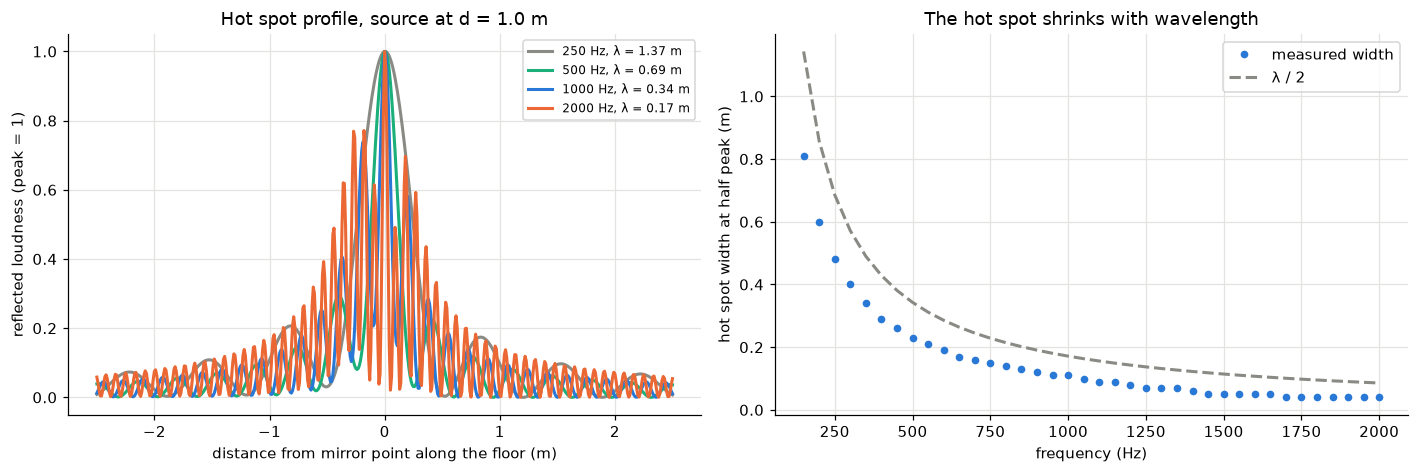

In [6]:
offset_m = 1.0
source = np.array([offset_m, 0.0])
line_x = np.linspace(-offset_m - 2.5, -offset_m + 2.5, 501)
line = np.column_stack([line_x, np.full_like(line_x, 0.05)])


def reflected_only(source, freq_hz, points):
    contrib, _ = wall_contributions(source, points, freq_hz)
    return contrib.sum(axis=1)


def half_max_width(x, intensity, centre, search):
    # Width at half height of the peak found within `search` of `centre`
    window = np.abs(x - centre) <= search
    peak = np.flatnonzero(window)[np.argmax(intensity[window])]
    above = intensity >= intensity[peak] / 2
    left = peak
    while left > 0 and above[left - 1]:
        left -= 1
    right = peak
    while right < len(x) - 1 and above[right + 1]:
        right += 1
    return x[right] - x[left]


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4))
for freq_hz, colour in zip([250, 500, 1000, 2000], [GREY, AQUA, BLUE, ORANGE]):
    intensity = np.abs(reflected_only(source, freq_hz, line)) ** 2
    ax1.plot(line_x + offset_m, intensity / intensity.max(), color=colour,
             label=f"{freq_hz} Hz, λ = {SPEED_OF_SOUND / freq_hz:.2f} m")
ax1.set_xlabel("distance from mirror point along the floor (m)")
ax1.set_ylabel("reflected loudness (peak = 1)")
ax1.set_title(f"Hot spot profile, source at d = {offset_m} m")
ax1.legend(fontsize=8)

freqs = np.linspace(150, 2000, 38)
widths = [half_max_width(line_x, np.abs(reflected_only(source, f, line)) ** 2,
                         centre=-offset_m, search=SPEED_OF_SOUND / f / 4)
          for f in freqs]
ax2.plot(freqs, widths, "o", color=BLUE, markersize=4, label="measured width")
ax2.plot(freqs, SPEED_OF_SOUND / freqs / 2, color=GREY, linestyle="--",
         label="λ / 2")
ax2.set_xlabel("frequency (Hz)")
ax2.set_ylabel("hot spot width at half peak (m)")
ax2.set_title("The hot spot shrinks with wavelength")
ax2.legend()
plt.tight_layout()
plt.show()

**What the plots show** (source at 1 m)

- **Left:** reflected loudness along the floor, centred on the mirror point, with each curve scaled so its peak is 1. All four frequencies peak exactly at the mirror point. The grey 250 Hz peak is about 0.5 m wide. The orange 2000 Hz peak is under 0.1 m wide, with side peaks reaching 0.6 to 0.8 on either side. Those side peaks are interference fringes. At high frequency the hot spot is a sharp centre surrounded by a ripple of near misses.
- **Right:** the width of the central peak at half its height, at 38 frequencies. The dots follow the shape of the dashed λ/2 curve and sit below it, at about a third of a wavelength. The spot is 0.8 m wide at 150 Hz and 4 cm wide at 2000 Hz.

A bass note makes a hot spot about a metre wide, so anyone near the mirror point hears it. A high overtone of a singing bowl makes a spot a few centimetres wide, so moving your head changes what you hear.

This 2D slice understates the effect. The real dome curves in both directions, so it focuses sound sideways as well as up and down. The real hot spot is a small blob rather than a line, and it collects sound from a much larger area of wall.

## 5. A pulse in the dome

The previous sections used one steady frequency. A clap or the strike of a singing bowl is a short **pulse**. Here the wave equation is solved step by step in the vertical slice: the pulse spreads out, hits the wall, and the reflected wave converges.

The simulation uses a grid with 4 cm cells, hard walls, and a pulse about 25 cm wide (its sound is mostly below 1 kHz). It takes a few seconds.

In [7]:
def simulate_pulse(source, probes, duration_s=0.11, dx=0.04, pulse_width=0.12,
                   frame_every_s=0.0005):
    # Acoustic wave equation on a staggered grid inside a hard circle of radius R.
    # Returns frame times, frames of the upper half (the real room),
    # probe times and the pressure recorded at each probe.
    n = int(np.ceil(2 * R / dx)) + 4
    coords = (np.arange(n) - (n - 1) / 2) * dx
    X, Y = np.meshgrid(coords, coords)
    inside = X ** 2 + Y ** 2 < R ** 2
    open_x = inside[:, 1:] & inside[:, :-1]  # faces between two inside cells
    open_y = inside[1:, :] & inside[:-1, :]
    dt = 0.5 * dx / SPEED_OF_SOUND

    p = np.exp(-((X - source[0]) ** 2 + (Y - source[1]) ** 2) / (2 * pulse_width ** 2))
    p *= inside
    vx = np.zeros((n, n - 1))
    vy = np.zeros((n - 1, n))
    div = np.zeros((n, n))

    upper = coords >= -dx / 2
    probe_cells = {name: (np.argmin(np.abs(coords - y)), np.argmin(np.abs(coords - x)))
                   for name, (x, y) in probes.items()}
    traces = {name: [] for name in probes}
    stride = max(1, round(frame_every_s / dt))
    n_steps = int(duration_s / dt)
    frames, frame_times = [p[upper].astype(np.float32)], [0.0]
    for step in range(1, n_steps + 1):
        vx -= dt / dx * (p[:, 1:] - p[:, :-1])
        vx *= open_x
        vy -= dt / dx * (p[1:, :] - p[:-1, :])
        vy *= open_y
        div[:] = 0
        div[:, :-1] += vx
        div[:, 1:] -= vx
        div[:-1, :] += vy
        div[1:, :] -= vy
        p -= SPEED_OF_SOUND ** 2 * dt / dx * div
        for name, (i, j) in probe_cells.items():
            traces[name].append(p[i, j])
        if step % stride == 0:
            frames.append(p[upper].astype(np.float32))
            frame_times.append(step * dt)
    probe_times = np.arange(1, n_steps + 1) * dt
    extent = [coords[0] - dx / 2, coords[-1] + dx / 2, -dx / 2, coords[-1] + dx / 2]
    return (np.array(frame_times), np.array(frames), extent, probe_times,
            {name: np.array(v) for name, v in traces.items()})


OFFSET = 1.0
off_centre = simulate_pulse((OFFSET, 0.0),
                            probes={"at the source": (OFFSET, 0.1),
                                    "at the mirror point": (-OFFSET, 0.1)})
print("done")

done


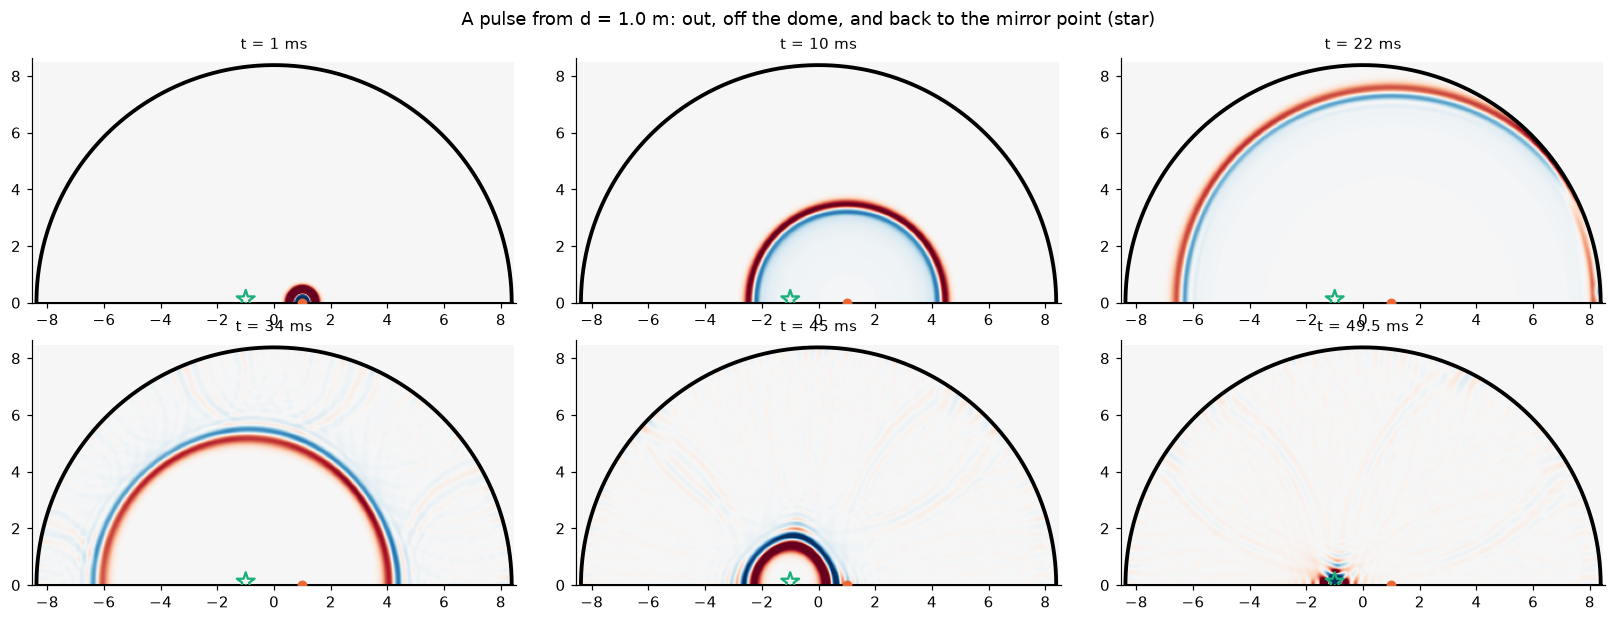

In [8]:
PULSE_VLIM = 0.06  # colour limit; the pulse weakens as it spreads, so clip the start


def draw_pulse_frame(ax, frame, extent, source, title):
    ax.imshow(frame, origin="lower", extent=extent, cmap="RdBu_r",
              vmin=-PULSE_VLIM, vmax=PULSE_VLIM)
    draw_room(ax, show_image=False)
    ax.scatter(*source, s=30, color=ORANGE, zorder=4)
    ax.set_xlim(-R * 1.02, R * 1.02)
    ax.set_ylim(0, R * 1.03)
    ax.grid(False)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(title, fontsize=10)


frame_times, frames, extent, _, _ = off_centre
fig, axes = plt.subplots(2, 3, figsize=(15, 5.6))
for ax, t_ms in zip(axes.flat, [1, 10, 22, 34, 45, 49.5]):
    i = np.argmin(np.abs(frame_times - t_ms / 1000))
    draw_pulse_frame(ax, frames[i], extent, (OFFSET, 0), f"t = {t_ms} ms")
    ax.scatter(-OFFSET, 0.12, s=150, marker="*", facecolor="none", edgecolor=AQUA,
               linewidth=1.5, zorder=4)
fig.suptitle(f"A pulse from d = {OFFSET} m: out, off the dome, and back to the mirror point (star)")
plt.tight_layout()
plt.show()

**What the figure shows** (source at 1 m, green star at the mirror point −1 m)

Six frozen moments of one clap. Red is compression and blue is rarefaction.

1. **1 ms:** the clap is a small blob at the source.
2. **10 ms:** a ring 3.4 m in radius centred on the source, with a red front and a blue trailing edge.
3. **22 ms:** the right side of the ring has reached the near wall, 7.4 m away, and is reflecting. The left side is still travelling to the far wall, 9.4 m away.
4. **34 ms:** the whole ring has reflected. It is now a shrinking ring centred on the star, with the order flipped: blue outside, red inside. The faint lines in the background are small scattered waves from the simulation's stepped version of the curved wall.
5. **45 ms:** the ring has shrunk to about 1.5 m around the star and is brighter, because the same sound is packed into a smaller circle.
6. **49.5 ms:** the ring collapses into a bright spot on the star. Every part of the wavefront arrives together. This is the constructive interference of section 3, seen in time.

Drag the slider below to step through time. The lower plot shows the pressure picked up by a microphone at the source and one at the mirror point, both 10 cm above the floor.

In [9]:
@interact(
    t_ms=FloatSlider(value=49.0, min=0.0, max=110.0, step=0.5, description="t (ms)",
                     continuous_update=False, style=SLIDER_STYLE),
)
def show_pulse(t_ms):
    frame_times, frames, extent, probe_times, traces = off_centre
    i = np.argmin(np.abs(frame_times - t_ms / 1000))
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8.2),
                                   gridspec_kw={"height_ratios": [1.5, 1]})
    draw_pulse_frame(ax1, frames[i], extent, (OFFSET, 0), f"t = {t_ms:.1f} ms")
    ax1.scatter(-OFFSET, 0.12, s=150, marker="*", facecolor="none", edgecolor=AQUA,
                linewidth=1.5, zorder=4)
    for (name, trace), colour in zip(traces.items(), [ORANGE, AQUA]):
        ax2.plot(probe_times * 1000, trace, color=colour, linewidth=1.2, label=name)
    ax2.axvline(t_ms, color="k", linewidth=1)
    ax2.set_ylim(-0.45, 0.45)
    ax2.set_xlabel("time (ms)")
    ax2.set_ylabel("pressure")
    ax2.legend(fontsize=8, loc="upper right")
    plt.tight_layout()
    plt.show()

interactive(children=(FloatSlider(value=49.0, continuous_update=False, description='t (ms)', max=110.0, step=0…

**What the plots show** (default t = 49 ms)

- **Top:** the room at the chosen time, the same view as above. At 49 ms the focused spot sits on the star.
- **Bottom:** the two microphone recordings. The black line marks the time shown on top.
  - **Orange (source)** starts with the clap itself, which runs off the top of the plot.
  - **Green (mirror point)** picks up the direct sound at 6 ms, a small blip after 2 m of travel. At 49 ms it spikes to more than four times that size, even though the reflected sound travelled 8 times further. That gain is the focusing.
  - **Orange** has a smaller burst at about 43 ms. This is sound reflected straight back by the wall nearest the source, 7.4 m out and 7.4 m back.
  - **Orange** spikes again at about 98 ms, when a second reflection brings the focused sound back to the source.

The vertical scale is cut at ±0.45 so the small blips are visible. The clap and the focused peaks run off the plot.

**Try this:**

- Step to 43 ms to see the near-wall reflection passing back through the source.
- Step to about 98 ms. The sound has reflected a second time and refocused at the source. It shuttles between the two points every $2R/c \approx 49$ ms.

### Hear the focus

The microphones in the simulation record pressure at every time step, which is a sound recording. The cell below runs the same pulse for 0.6 s and plays what a microphone hears at the mirror point and 1 m past it. Both use the same volume setting. The simulated pulse holds little sound above 1 kHz, so it plays as a soft thump rather than a sharp clap. The run takes about 10 s.

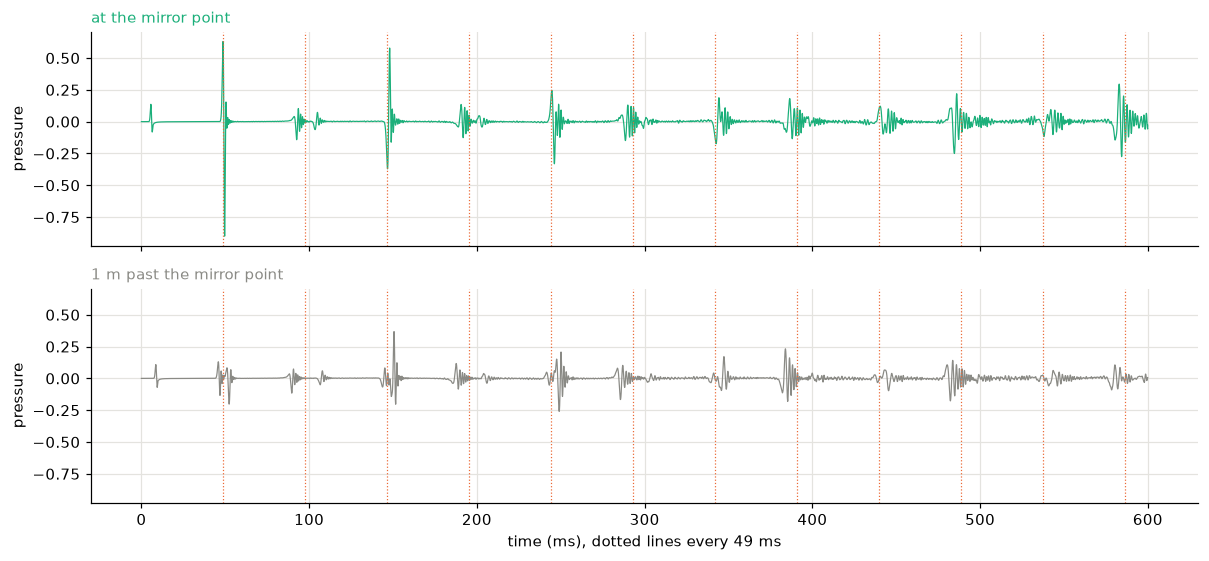

at the mirror point


1 m past the mirror point


In [10]:
from IPython.display import Audio, display
from scipy.signal import resample_poly

AUDIO_RATE = 22050
long_run = simulate_pulse((OFFSET, 0.0), duration_s=0.6, frame_every_s=1.0,
                          probes={"at the mirror point": (-OFFSET, 0.1),
                                  "1 m past the mirror point": (-OFFSET - 1.0, 0.1)})
# The simulation takes 17150 steps per second: resample to a standard audio rate
recordings = {name: resample_poly(trace, 441, 343) for name, trace in long_run[4].items()}
volume = 0.9 / max(np.abs(r).max() for r in recordings.values())

fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True, sharey=True)
for ax, (name, recording), colour in zip(axes, recordings.items(), [AQUA, GREY]):
    t_ms = np.arange(len(recording)) / AUDIO_RATE * 1000
    ax.plot(t_ms, recording * volume, color=colour, linewidth=0.8)
    for n in range(1, 13):
        ax.axvline(n * 2 * R / SPEED_OF_SOUND * 1000, color=ORANGE, linestyle=":",
                   linewidth=0.8)
    ax.set_ylabel("pressure")
    ax.set_title(name, fontsize=10, loc="left", color=colour)
axes[-1].set_xlabel("time (ms), dotted lines every 49 ms")
plt.tight_layout()
plt.show()
for name, recording in recordings.items():
    print(name)
    display(Audio(recording * volume, rate=AUDIO_RATE, normalize=False))

**What the plots show** (both on the same scale, dotted lines every 49 ms)

- **At the mirror point (top):** a small blip at 6 ms is the direct sound. At 49 ms the focused reflection arrives as the largest swing in the recording, about seven times the size of the direct sound. Strong returns follow at 147 ms and 245 ms, 98 ms apart, as the sound shuttles between source and mirror point. After about 300 ms the arrivals spread into smaller ripples.
- **1 m past the mirror point (bottom):** the same moments carry much less. At 49 ms the swing is about a sixth of the mirror point's. The biggest arrival here, at 147 ms, is still under half of the mirror point's first focus.

In the players, the mirror point gives a faint tap followed 49 ms later by a much louder thump and a fading series of repeats. One metre away the thump is missing and the repeats are more even. The simulated walls absorb nothing, so the sound would not die away if the run were longer.

### The centre: your own voice comes back

Now put the source at the centre and record there.

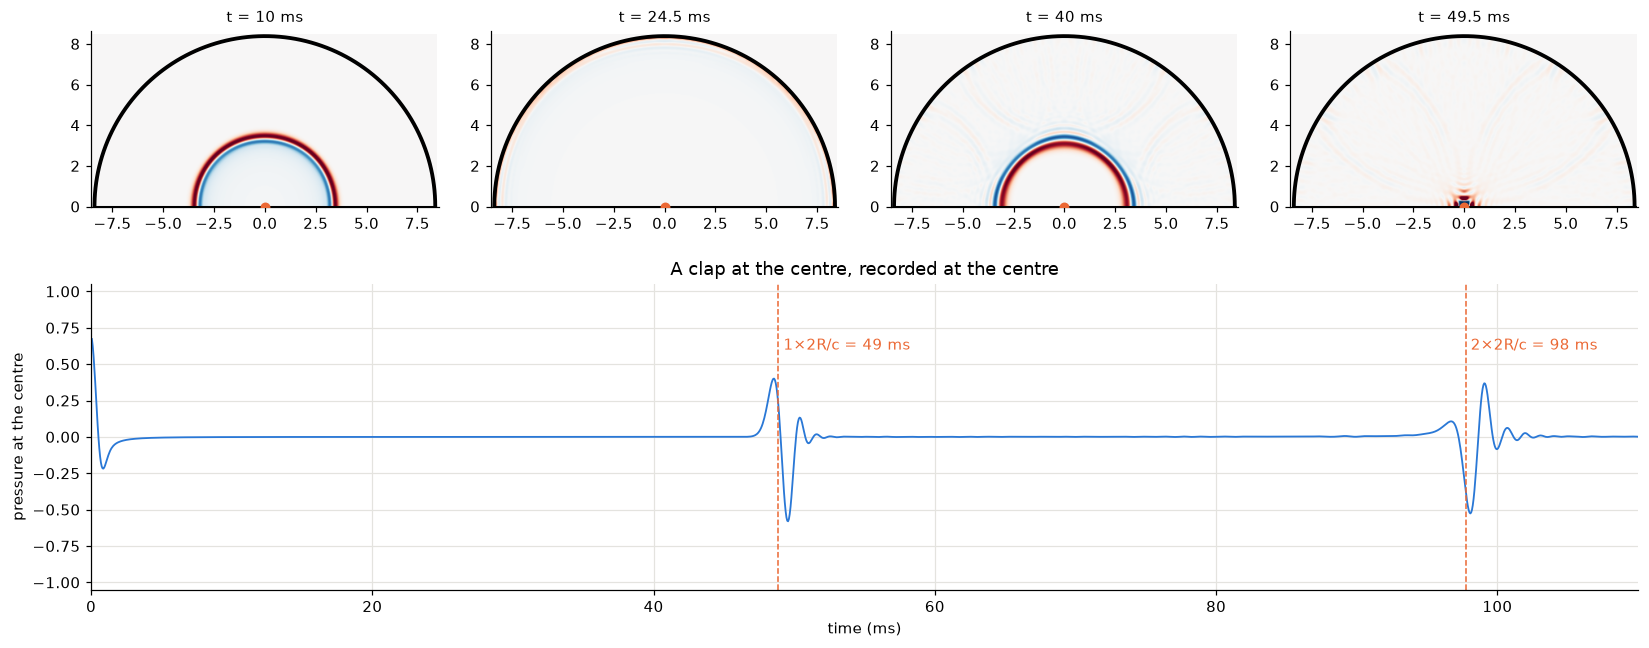

In [11]:
centre = simulate_pulse((0.0, 0.0), probes={"at the centre": (0.0, 0.1)})
frame_times, frames, extent, probe_times, traces = centre

fig = plt.figure(figsize=(15, 6.4))
grid = fig.add_gridspec(2, 4, height_ratios=[1, 1])
for col, t_ms in enumerate([10, 24.5, 40, 49.5]):
    ax = fig.add_subplot(grid[0, col])
    i = np.argmin(np.abs(frame_times - t_ms / 1000))
    draw_pulse_frame(ax, frames[i], extent, (0, 0), f"t = {t_ms} ms")

ax = fig.add_subplot(grid[1, :])
ax.plot(probe_times * 1000, traces["at the centre"], color=BLUE, linewidth=1.2)
round_trip_ms = 2 * R / SPEED_OF_SOUND * 1000
for n in (1, 2):
    ax.axvline(n * round_trip_ms, color=ORANGE, linestyle="--", linewidth=1)
    ax.text(n * round_trip_ms, 0.6, f" {n}×2R/c = {n * round_trip_ms:.0f} ms",
            color=ORANGE)
ax.set_xlim(0, 110)
ax.set_ylim(-1.05, 1.05)
ax.set_xlabel("time (ms)")
ax.set_ylabel("pressure at the centre")
ax.set_title("A clap at the centre, recorded at the centre")
plt.tight_layout()
plt.show()

**What the figure shows**

- **Top row:** a clap at the centre. At 10 ms it is a ring 3.4 m in radius. At 24.5 ms the whole ring reaches the wall at the same moment and shows as a faint line just inside the dome. At 40 ms the reflected ring is shrinking back toward the centre, blue outside and red inside. At 49.5 ms it collapses to a point at the centre.
- **Bottom:** pressure at the centre. The clap is at t = 0. Then there is silence for 48 ms, an echo at 49 ms, more silence, and a second echo at 98 ms. Nothing arrives in between because every path from the centre to the wall and back has the same length, $2R$.

The echo reaches 0.4 and −0.57, more than half the strength of the clap. Its shape has changed from a single peak to an up-then-down swing. A wave that passes through a focus picks up an extra phase shift, called the **Gouy phase**, which reshapes the pulse.

The return time is

$$t = \frac{2R}{c} = \frac{2 \times 8.38\ \text{m}}{343\ \text{m/s}} \approx 49\ \text{ms}$$

A delay of about 50 ms is close to where the ear stops blending a reflection into the original sound and starts hearing a separate echo. Someone speaking at the centre hears their voice come back clearly from all around.

## Summary

| Idea | Formula | Integratron scale |
|---|---|---|
| Floor as a mirror | dome + image = sphere | floor at the dome's base, through the centre |
| Focus of an off-centre source | mirror point at $-d$ | sharp for $d$ up to about 1 m, smeared into a caustic beyond 2 m |
| Phase of a reflected wave | $2\pi (r_1 + r_2)/\lambda$ | λ = 0.69 m at 500 Hz |
| Constructive interference | path spread $< \lambda/2$ | perfect at the centre: every path is $2R$ |
| Hot spot size | about λ/3 at half height | 0.8 m at 150 Hz, 4 cm at 2 kHz |
| Round-trip time | $2R/c$ | 49 ms |

1. The flat floor mirrors the dome, so the room behaves like a sphere.
2. The curved wall sends sound from a point within about 1 m of the centre to its mirror point on the other side. Further out the focus smears and moves toward the centre.
3. At the mirror point, waves from the whole wall have nearly equal path lengths. They arrive in step and add, so the sound there is 15 to 20 dB louder than the room's typical level.
4. The hot spot is about a third of a wavelength wide. Low notes fill a large area and high notes hit a small spot.
5. A pulse shuttles between source and mirror point every 49 ms. From the centre it comes straight back to the speaker.

**Next:** why the dome keeps ringing: standing waves, room modes, and how long the sound takes to die away.